In [1]:
import numpy as np
import pandas as pd
import mne
import h5py
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nilearn.plotting import plot_markers
from mne_bids import BIDSPath

from himalaya.backend import set_backend, get_backend
from himalaya.ridge import RidgeCV
from himalaya.scoring import correlation_score

from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import re
import mne
import numpy as np
from mne_bids import BIDSPath
from nilearn import datasets, image
from scipy.spatial import KDTree
from collections import Counter

import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import fdrcorrection
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import numpy as np
import pandas as pd

In [2]:
transcript_path = "stimuli/podcast_transcript.csv"

df = pd.read_csv(transcript_path)
df.head(20)

,word,start,end
0,Act,3.710,3.790
1,"one,",3.990,4.190
2,monkey,4.651,4.931
3,in,4.951,5.011
4,the,5.051,5.111
5,middle.,5.151,5.391
6,So,6.592,6.732
7,there's,6.752,6.912
8,some,6.892,7.052
9,places,7.072,7.342


In [ ]:
glove_path = 'glove.6B.50d.txt'
#create the glove model based on our glove file in google drive
def load_glove_to_dict(file_path):
    glove_dict = {}
    print(f"Loading {file_path}...")

    with open(file_path, 'r', encoding='utf-8') as f:
        for line in f:
            # Each line looks like: word 0.123 0.456 ...
            values = line.split()
            word = values[0]
            # Convert the numbers into a numpy array
            vector = np.asarray(values[1:], dtype='float32')
            glove_dict[word] = vector

    print(f"Done! {len(glove_dict)} words loaded.")
    return glove_dict


glove_model = load_glove_to_dict(glove_path)



def clean_word(w):
    """Better clean up: Lowercase + normalize apostrophes + strip punctuation."""
    w = str(w).lower()
    # Normalize curly apostrophes to straight ones for GloVe compatibility
    w = re.sub(r"[’‘’ʻ]", "'", w)
    # Strip punctuation but keep internal apostrophes (don't strip ')
    return w.strip(" .,!?;:\"()-[]")

# Update the dataframe with the better cleanup
df["word_clean"] = df["word"].apply(clean_word)

# Define words that should be excluded as fillers 
EXCLUDE_FILLERS = {'ch', 'hm', 'mhm', 'mm','uh', 'um'}

def get_glove_vector(w):
    if w in EXCLUDE_FILLERS or w not in glove_model:
        return None
    return glove_model[w]

# Apply the function to create a new column
df["glove_embedding"] = df["word_clean"].apply(get_glove_vector)


df_glove = df.dropna(subset=["glove_embedding"]).copy()


X_glove = np.stack(df_glove["glove_embedding"].values).astype("float32")


oov_count = len(df) - len(df_glove)

print("=" * 50)
print(f"Total words in transcript : {len(df)}")
print(f"Words WITH GloVe embedding: {len(df_glove)}")
print(f"Words WITHOUT (OOV/Fill)  : {oov_count}")
print(f"X_glove shape             : {X_glove.shape}")
print("=" * 50)


df_glove.head(8)

Loading glove.6B.50d.txt...
Done! 400000 words loaded.
Total words in transcript : 5136
Words WITH GloVe embedding: 4867
Words WITHOUT (OOV/Fill)  : 269
X_glove shape             : (4867, 50)


,word,start,end,word_clean,glove_embedding
0,Act,3.710,3.790,act,"[-0.60647, -0.65705, -1.1819, -0.61002, -0.197..."
1,"one,",3.990,4.190,one,"[0.31474, 0.41662, 0.1348, 0.15854, 0.88812, 0..."
2,monkey,4.651,4.931,monkey,"[0.28704, -0.60904, -0.74821, 0.17686, 0.92118..."
3,in,4.951,5.011,in,"[0.33042, 0.24995, -0.60874, 0.10923, 0.036372..."
4,the,5.051,5.111,the,"[0.418, 0.24968, -0.41242, 0.1217, 0.34527, -0..."
5,middle.,5.151,5.391,middle,"[-0.15502, 1.0436, -0.22143, -0.89604, 0.49455..."
6,So,6.592,6.732,so,"[0.60308, -0.32024, 0.088857, -0.55176, 0.5318..."
8,some,6.892,7.052,some,"[0.92871, -0.10834, 0.21497, -0.50237, 0.10379..."


In [4]:

transcript_path = "stimuli/gpt2-xl/transcript.tsv"
df_gpt = pd.read_csv(transcript_path, sep="\t", index_col=0)


In [5]:
df_gpt.shape

(5491, 10)

In [6]:
embedding_path = "stimuli/gpt2-xl/features.hdf5"
modelname, layer = 'gpt2-xl', 48
with h5py.File(embedding_path, "r") as f:
    contextual_embeddings = f[f"layer-{layer}"][...]
print(f"LLM embedding matrix has shape: {contextual_embeddings.shape}")

LLM embedding matrix has shape: (5491, 1600)


In [ ]:
# 1. PCA: Reduce from 1600 to 50 dimensions
#  raw contextual_embeddings (5491, 1600)
pca = PCA(n_components=50)
embeddings_50d = pca.fit_transform(contextual_embeddings)
print(f"Reduced embedding shape: {embeddings_50d.shape}") # (5491, 50)

# 2. Group by word_idx and average the 50-d embeddings
# This handles cases where one word was split into multiple tokens
aligned_embeddings_50d = []
for _, group in df_gpt.groupby("word_idx"):
    indices = group.index.to_numpy()
    # Average the 50-d features for tokens belonging to the same word
    average_emb = embeddings_50d[indices].mean(0) 
    aligned_embeddings_50d.append(average_emb)

# Convert list to a stack of arrays
aligned_embeddings_50d = np.stack(aligned_embeddings_50d)
print(f"Final word-level embedding matrix shape: {aligned_embeddings_50d.shape}") # (5136, 50)

# 3. Create a word-level DataFrame
# group df_gpt by word_idx to get one row per unique word
df_words = df_gpt.groupby("word_idx").first().reset_index()

# 4. Insert the 50-d embeddings into the new DataFrame
# store them as a list of arrays so each row has its own 50-d vector
df_words["gpt_embedding_50d"] = list(aligned_embeddings_50d)

print(f"df_words shape: {df_words.shape}")
df_words.head()

Reduced embedding shape: (5491, 50)
Final word-level embedding matrix shape: (5136, 50)
df_words shape: (5136, 11)


,word_idx,word,start,end,hftoken,token_id,rank,true_prob,top_pred,entropy,gpt_embedding_50d
0,0,Act,3.710,3.790,ĠAct,2191,1644,0.000012,0,2.402717,"[-1.9689006, -2.720397, -2.0837488, -4.4684653..."
1,1,"one,",3.990,4.190,Ġone,530,92,0.000342,352,3.732053,"[-0.27875954, -0.8526557, -2.1738038, 0.674707..."
2,2,monkey,4.651,4.931,Ġmonkey,21657,4022,0.000018,3715,6.621269,"[-1.152554, 1.3146999, -3.9557898, 1.9347883, ..."
3,3,in,4.951,5.011,Ġin,287,15,0.004237,0,4.444838,"[-6.7560816, 2.8779044, 4.293638, -1.2895403, ..."
4,4,the,5.051,5.111,Ġthe,262,0,0.392205,262,3.781622,"[-6.889698, 5.555914, -1.247372, 5.097419, 6.2..."


In [ ]:
# Apply cleaning
df_words["word_clean"] = df_words["word"].apply(clean_word)

# Exclude fillers, defined  above
# Create a "Mask" (a list of True/False) 
# True if: word is NOT a filler AND word IS in glove_model
mask = df_words["word_clean"].apply(
    lambda w: w not in EXCLUDE_FILLERS and w in glove_model
)

# Apply the mask to create your final filtered dataframe
df_gpt_final = df_words[mask].copy()


# Verification 
print(f"Initial Word-Level rows : {len(df_words)}")
print(f"Final aligned rows      : {len(df_gpt_final)}")
print(f"Rows dropped            : {len(df_words) - len(df_gpt_final)}")

# Checking the first few rows to ensure GPT and GloVe embeddings are both there
df_gpt_final.head(3)

Initial Word-Level rows : 5136
Final aligned rows      : 4867
Rows dropped            : 269


,word_idx,word,start,end,hftoken,token_id,rank,true_prob,top_pred,entropy,gpt_embedding_50d,word_clean
0,0,Act,3.710,3.790,ĠAct,2191,1644,0.000012,0,2.402717,"[-1.9689006, -2.720397, -2.0837488, -4.4684653...",act
1,1,"one,",3.990,4.190,Ġone,530,92,0.000342,352,3.732053,"[-0.27875954, -0.8526557, -2.1738038, 0.674707...",one
2,2,monkey,4.651,4.931,Ġmonkey,21657,4022,0.000018,3715,6.621269,"[-1.152554, 1.3146999, -3.9557898, 1.9347883, ...",monkey


In [9]:
print(df_gpt_final.shape)
print(df_glove.shape)

(4867, 12)
(4867, 5)


In [ ]:
# Count occurrences and filter in one step
# 'count' will return the number of rows for each word in "word_clean"
df_glove_filtered = df_glove[df_glove.groupby('word_clean')['word_clean'].transform('count') >= 5].copy()

#  Reset the index so it's clean (0, 1, 2...)
df_glove_filtered = df_glove_filtered.reset_index(drop=True)

# Verification
print(f"Original rows: {len(df_glove)}")
print(f"Filtered rows: {len(df_glove_filtered)}")
print(f"Unique words left: {df_glove_filtered['word_clean'].nunique()}")

# Double check the smallest count is actually 5
print("\nSmallest word count in new DF:")
print(df_glove_filtered['word_clean'].value_counts().min())

Original rows: 4867
Filtered rows: 3321
Unique words left: 167

Smallest word count in new DF:
5


In [ ]:
# 1. Filter for common words (count >= 5)
# use 'transform' so every row gets the count of its 'word_clean'
df_gpt_filtered = df_gpt_final[df_gpt_final.groupby('word_clean')['word_clean'].transform('count') >= 5].copy()

# Reset the index
# This ensures that if we need to align with MNE epochs later, the index is clean
df_gpt_filtered = df_gpt_filtered.reset_index(drop=True)
print(df_glove_filtered.shape)


(3321, 5)


# All the embeddings

In [12]:
#GLOVE
X_glove_filtered = np.stack(df_glove_filtered['glove_embedding'].values).astype("float32")
X_glove_filtered.shape

(3321, 50)

In [13]:
#GPT CONTEXTUAL
X_gpt_contextual = np.stack(df_gpt_filtered['gpt_embedding_50d'].values).astype("float32")
X_gpt_contextual.shape

(3321, 50)

In [14]:

X_gpt_avg = X_gpt_contextual.copy()   # start from contextual, modify in place
words_clean = df_gpt_filtered['word_clean'].values 
unique, counts = np.unique(words_clean, return_counts=True)


for word in unique:
    # Find all row positions where this word occurs
    idx = np.where(words_clean == word)[0]   # e.g. [4, 23, 67, 201, 340, ...]

    # Average all their GPT-2 embeddings into one vector
    avg_vec = X_gpt_contextual[idx].mean(axis=0)   # shape (50,)

    # Replace every occurrence with that average
    X_gpt_avg[idx] = avg_vec
X_gpt_avg.shape

(3321, 50)

In [ ]:


X_gpt_shuffled = X_gpt_contextual.copy()
rng = np.random.default_rng(seed=42)

words_clean = df_gpt_filtered['word_clean'].values
unique, counts = np.unique(words_clean, return_counts=True)


for word in unique:
    idx = np.where(words_clean == word)[0]   # all positions of this word


    # shuffle idx such that NO element maps to itself 
    shuffled_idx = idx
    while np.any(shuffled_idx == idx):
        shuffled_idx = rng.permutation(idx)

    # Assign: occurrence at position idx[i] gets the embedding from shuffled_idx[i]
    X_gpt_shuffled[idx] = X_gpt_contextual[shuffled_idx]

X_gpt_shuffled.shape



(3321, 50)

In [ ]:
#test to ensure correct shape and all embeddings are different
print(X_gpt_shuffled.shape)
print(X_gpt_shuffled[0])
print(X_gpt_avg.shape)
print(X_gpt_avg[0])
print(X_gpt_contextual.shape)
print(X_gpt_contextual[0])
print(X_glove_filtered.shape)
print(X_glove_filtered[0])

(3321, 50)
[-7.7615814   3.5198092  -2.880723    3.3155057   1.817089   -1.5511677
  0.43251455  3.6162157   1.7182157  -0.26851162 -0.53984517 -3.6789422
  5.2993736  -0.11259416  2.5303593   1.1984107  -5.501315   -2.0291443
  7.0774403  -0.18742475 -6.1634445   0.69195855  2.064628    1.5268855
 -0.4733829   2.2402806  -0.8172517  -0.02879073  2.9210975  -0.5208424
  1.4443649  -1.668868   -1.1929339  -5.522518    0.32253954 -0.71008277
  0.5873694   0.21814673  0.63698316  2.0892923   2.6213765   1.2243071
  4.7692413  -0.19188502 -0.9776817  -1.892847    1.8101528   3.3773646
 -0.03684543  2.7572925 ]
(3321, 50)
[-3.0947437   0.3705578  -1.430784    2.3283246   3.244324    2.3879483
 -0.10625318  0.56057495 -0.8363551   0.27637872  1.4818825  -2.0645535
  4.326612    0.2751199   2.1203008  -0.88753176 -3.1857047  -0.89236397
  3.7077107   2.0273385  -1.751527    0.0825168   0.48763832  1.7744142
 -0.39445987 -0.45334497  0.4610904   0.44080272  0.98932964  1.1660999
  0.9139373  -

In [ ]:
bids_root = "add path where your BIDS dataset is stored"

In [18]:
alphas   = np.logspace(1, 10, 10)
inner_cv = KFold(n_splits=5, shuffle=False)
model    = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas, fit_intercept=True, cv=inner_cv)
)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('ridgecv', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,alphas,"array([1.e+01...e+09, 1.e+10])"
,fit_intercept,True
,solver,'svd'
,solver_params,None


In [19]:
def train_encoding(X, Y, epochs_shape):
    corrs = []
    kfold = KFold(10, shuffle=False)
    for train_idx, test_idx in kfold.split(X):
        X_train, X_test = X[train_idx], X[test_idx]
        Y_train, Y_test = Y[train_idx], Y[test_idx]
        scaler  = StandardScaler()
        Y_train = scaler.fit_transform(Y_train)
        Y_test  = scaler.transform(Y_test)
        model.fit(X_train, Y_train)
        Y_pred  = model.predict(X_test)
        corr    = correlation_score(Y_test, Y_pred).reshape(epochs_shape)
        if "torch" in get_backend().__name__:
            corr = corr.numpy(force=True)
        corrs.append(corr)
    return np.stack(corrs)   # (n_folds, n_sig_elec, 161)

In [20]:
import os

RESULTS_DIR = "results_6b_redone_48_layers"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ── Figure 6b: four GPT/GloVe embedding conditions ───────────────────────────
sig_elec_master = pd.read_csv("significant_electrodes_glove.csv")
sig_elec_master["subject"] = sig_elec_master["subject"].astype(str).str.zfill(2)

subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]
lags_ms     = np.linspace(-2000, 2000, 161)

EMBEDDINGS = {
    "gpt_contextual" : X_gpt_contextual,
    "gpt_avg"        : X_gpt_avg,
    "gpt_shuffled"   : X_gpt_shuffled,
    "glove_filtered" : X_glove_filtered,
}

all_corrs_fig6 = {key: [] for key in EMBEDDINGS}

for sid in subject_ids:

    sub_sig = sig_elec_master[sig_elec_master["subject"] == sid]
    if len(sub_sig) == 0:
        print(f"sub-{sid}: no significant electrodes, skipping")
        continue

    sig_indices = sub_sig["elec_idx"].values
    print(f"\nsub-{sid}: {len(sig_indices)} significant electrodes")

    file_path = BIDSPath(
        root=f"{bids_root}derivatives/ecogprep",
        subject=sid, task="podcast", datatype="ieeg",
        description="highgamma", suffix="ieeg", extension=".fif"
    )
    raw = mne.io.read_raw_fif(file_path.fpath, verbose=False)

    ch2loc    = {ch['ch_name']: ch['loc'][:3] for ch in raw.info['chs']}
    coords_mm = np.vstack([ch2loc[ch] for ch in raw.ch_names]) * 1000
    lh_mask   = coords_mm[:, 0] < 0
    raw = raw.copy().pick([ch for ch, k in zip(raw.ch_names, lh_mask) if k])
    raw = raw.copy().pick([raw.ch_names[i] for i in sig_indices])
    print(f"  {len(raw.ch_names)} channels loaded")

    sfreq  = raw.info['sfreq']
    events = np.zeros((len(df_gpt_filtered), 3), dtype=int)
    events[:, 0] = (df_gpt_filtered['start'].values * sfreq).astype(int)

    epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,
                        baseline=None, proj=False, event_id=None,
                        preload=True, event_repeated="merge")

    times       = epochs.times
    lag_centers = np.arange(-2.0, 2.0 + 0.025/2, 0.025)
    WIN_HALF    = 0.100
    lag_masks   = [(times >= τ - WIN_HALF) & (times <= τ + WIN_HALF)
                   for τ in lag_centers]

    epochs_data = epochs.get_data(copy=True)
    n_words, n_sig_elec, _ = epochs_data.shape
    epochs_shape = (n_sig_elec, 161)

    epochs_windowed = np.stack(
        [epochs_data[:, :, m].mean(axis=2) for m in lag_masks], axis=2
    ).astype(np.float32)

    Y = epochs_windowed.reshape(n_words, n_sig_elec * 161)
    if "torch" in get_backend().__name__:
        Y = Y.astype(np.float32)

    for emb_name, X_full in EMBEDDINGS.items():

        X_sel = X_full[epochs.selection].astype(np.float32)
        print(f"  [{emb_name}] X:{X_sel.shape}  Y:{Y.shape}")

        corrs = train_encoding(X_sel, Y, epochs_shape)

        save_path = f"{RESULTS_DIR}/corrs_{emb_name}_sub{sid}.npy"
        np.save(save_path, corrs)
        print(f"  Saved {save_path}  shape: {corrs.shape}")

        all_corrs_fig6[emb_name].append(corrs)

print("\n✓ All subjects and conditions complete.")

sub-02: no significant electrodes, skipping

sub-03: 41 significant electrodes
  41 channels loaded
Not setting metadata
3321 matching events found
No baseline correction applied
Loading data for 3321 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_1395/1643629753.py:50: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  [gpt_contextual] X:(3315, 50)  Y:(3315, 6601)
  Saved results_6b_redone_48_layers/corrs_gpt_contextual_sub03.npy  shape: (10, 41, 161)
  [gpt_avg] X:(3315, 50)  Y:(3315, 6601)
  Saved results_6b_redone_48_layers/corrs_gpt_avg_sub03.npy  shape: (10, 41, 161)
  [gpt_shuffled] X:(3315, 50)  Y:(3315, 6601)
  Saved results_6b_redone_48_layers/corrs_gpt_shuffled_sub03.npy  shape: (10, 41, 161)
  [glove_filtered] X:(3315, 50)  Y:(3315, 6601)
  Saved results_6b_redone_48_layers/corrs_glove_filtered_sub03.npy  shape: (10, 41, 161)

sub-04: 15 significant electrodes
  15 channels loaded
Not setting metadata
3321 matching events found
No baseline correction applied
Loading data for 3321 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_1395/1643629753.py:50: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  [gpt_contextual] X:(3315, 50)  Y:(3315, 2415)
  Saved results_6b_redone_48_layers/corrs_gpt_contextual_sub04.npy  shape: (10, 15, 161)
  [gpt_avg] X:(3315, 50)  Y:(3315, 2415)
  Saved results_6b_redone_48_layers/corrs_gpt_avg_sub04.npy  shape: (10, 15, 161)
  [gpt_shuffled] X:(3315, 50)  Y:(3315, 2415)
  Saved results_6b_redone_48_layers/corrs_gpt_shuffled_sub04.npy  shape: (10, 15, 161)
  [glove_filtered] X:(3315, 50)  Y:(3315, 2415)
  Saved results_6b_redone_48_layers/corrs_glove_filtered_sub04.npy  shape: (10, 15, 161)

sub-05: 3 significant electrodes
  3 channels loaded
Not setting metadata
3321 matching events found
No baseline correction applied
Loading data for 3321 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_1395/1643629753.py:50: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  [gpt_contextual] X:(3315, 50)  Y:(3315, 483)
  Saved results_6b_redone_48_layers/corrs_gpt_contextual_sub05.npy  shape: (10, 3, 161)
  [gpt_avg] X:(3315, 50)  Y:(3315, 483)
  Saved results_6b_redone_48_layers/corrs_gpt_avg_sub05.npy  shape: (10, 3, 161)
  [gpt_shuffled] X:(3315, 50)  Y:(3315, 483)
  Saved results_6b_redone_48_layers/corrs_gpt_shuffled_sub05.npy  shape: (10, 3, 161)
  [glove_filtered] X:(3315, 50)  Y:(3315, 483)
  Saved results_6b_redone_48_layers/corrs_glove_filtered_sub05.npy  shape: (10, 3, 161)

sub-06: 25 significant electrodes
  25 channels loaded
Not setting metadata
3321 matching events found
No baseline correction applied
Loading data for 3321 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_1395/1643629753.py:50: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  [gpt_contextual] X:(3315, 50)  Y:(3315, 4025)
  Saved results_6b_redone_48_layers/corrs_gpt_contextual_sub06.npy  shape: (10, 25, 161)
  [gpt_avg] X:(3315, 50)  Y:(3315, 4025)
  Saved results_6b_redone_48_layers/corrs_gpt_avg_sub06.npy  shape: (10, 25, 161)
  [gpt_shuffled] X:(3315, 50)  Y:(3315, 4025)
  Saved results_6b_redone_48_layers/corrs_gpt_shuffled_sub06.npy  shape: (10, 25, 161)
  [glove_filtered] X:(3315, 50)  Y:(3315, 4025)
  Saved results_6b_redone_48_layers/corrs_glove_filtered_sub06.npy  shape: (10, 25, 161)

sub-07: 19 significant electrodes
  19 channels loaded
Not setting metadata
3321 matching events found
No baseline correction applied
Loading data for 3321 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_1395/1643629753.py:50: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  [gpt_contextual] X:(3315, 50)  Y:(3315, 3059)
  Saved results_6b_redone_48_layers/corrs_gpt_contextual_sub07.npy  shape: (10, 19, 161)
  [gpt_avg] X:(3315, 50)  Y:(3315, 3059)
  Saved results_6b_redone_48_layers/corrs_gpt_avg_sub07.npy  shape: (10, 19, 161)
  [gpt_shuffled] X:(3315, 50)  Y:(3315, 3059)
  Saved results_6b_redone_48_layers/corrs_gpt_shuffled_sub07.npy  shape: (10, 19, 161)
  [glove_filtered] X:(3315, 50)  Y:(3315, 3059)
  Saved results_6b_redone_48_layers/corrs_glove_filtered_sub07.npy  shape: (10, 19, 161)

sub-08: 16 significant electrodes
  16 channels loaded
Not setting metadata
3321 matching events found
No baseline correction applied
Loading data for 3321 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_1395/1643629753.py:50: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  [gpt_contextual] X:(3315, 50)  Y:(3315, 2576)
  Saved results_6b_redone_48_layers/corrs_gpt_contextual_sub08.npy  shape: (10, 16, 161)
  [gpt_avg] X:(3315, 50)  Y:(3315, 2576)
  Saved results_6b_redone_48_layers/corrs_gpt_avg_sub08.npy  shape: (10, 16, 161)
  [gpt_shuffled] X:(3315, 50)  Y:(3315, 2576)
  Saved results_6b_redone_48_layers/corrs_gpt_shuffled_sub08.npy  shape: (10, 16, 161)
  [glove_filtered] X:(3315, 50)  Y:(3315, 2576)
  Saved results_6b_redone_48_layers/corrs_glove_filtered_sub08.npy  shape: (10, 16, 161)

sub-09: 55 significant electrodes
  55 channels loaded
Not setting metadata
3321 matching events found
No baseline correction applied
Loading data for 3321 events and 2049 original time points ...


/var/folders/28/5h1f5z1n1sg6x_cxrjkyfgbh0000gn/T/ipykernel_1395/1643629753.py:50: RuntimeWarning: The events passed to the Epochs constructor are not chronologically ordered.
  epochs = mne.Epochs(raw, events, tmin=-2.0, tmax=2.0,


6 bad epochs dropped
  [gpt_contextual] X:(3315, 50)  Y:(3315, 8855)
  Saved results_6b_redone_48_layers/corrs_gpt_contextual_sub09.npy  shape: (10, 55, 161)
  [gpt_avg] X:(3315, 50)  Y:(3315, 8855)
  Saved results_6b_redone_48_layers/corrs_gpt_avg_sub09.npy  shape: (10, 55, 161)
  [gpt_shuffled] X:(3315, 50)  Y:(3315, 8855)
  Saved results_6b_redone_48_layers/corrs_gpt_shuffled_sub09.npy  shape: (10, 55, 161)
  [glove_filtered] X:(3315, 50)  Y:(3315, 8855)
  Saved results_6b_redone_48_layers/corrs_glove_filtered_sub09.npy  shape: (10, 55, 161)

✓ All subjects and conditions complete.


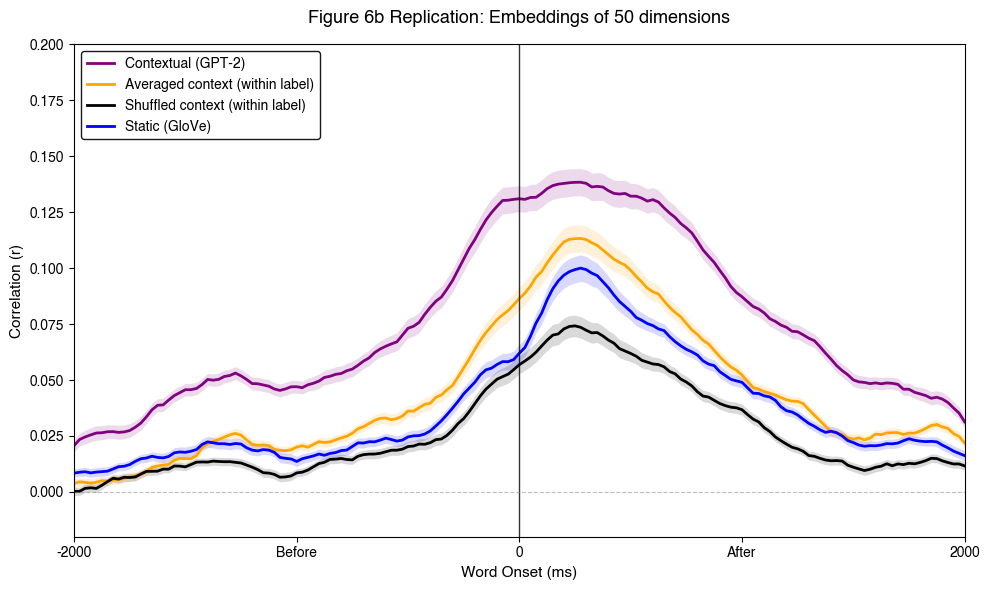

In [ ]:
#PLOTTING

#this code run even if the above code is not re-run (To save compute, correlations were saved through-out)
RESULTS_DIR = "results_6b_redone_48_layers"
subject_ids = ["02", "03", "04", "05", "06", "07", "08", "09"]
lags_ms     = np.linspace(-2000, 2000, 161)

EMBEDDING_NAMES = ["gpt_contextual", "gpt_avg", "gpt_shuffled", "glove_filtered"]

PLOT_STYLE = {
    "gpt_contextual" : ("purple", "Contextual (GPT-2)"),
    "gpt_avg"        : ("orange", "Averaged context (within label)"),
    "gpt_shuffled"   : ("black",  "Shuffled context (within label)"),
    "glove_filtered" : ("blue",   "Static (GloVe)"),
}

all_corrs_fig6_loaded = {key: [] for key in EMBEDDING_NAMES}

for sid in subject_ids:
    for emb_name in EMBEDDING_NAMES:
        fpath = os.path.join(RESULTS_DIR, f"corrs_{emb_name}_sub{sid}.npy")
        if os.path.exists(fpath):
            all_corrs_fig6_loaded[emb_name].append(np.load(fpath))

# Stats Function
def pool_and_stats(corrs_list):
    pooled        = np.concatenate(corrs_list, axis=1)   
    mean_per_elec = pooled.mean(axis=0)                  
    mean          = mean_per_elec.mean(axis=0)           
    err           = mean_per_elec.std(axis=0) / np.sqrt(mean_per_elec.shape[0])
    return pooled, mean, err

plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
fig, ax = plt.subplots(figsize=(10, 6))

pooled_results = {}
valid_data_found = False

for emb_name, (color, label) in PLOT_STYLE.items():
    if len(all_corrs_fig6_loaded[emb_name]) == 0:
        continue
    
    valid_data_found = True
    pooled, mean, err = pool_and_stats(all_corrs_fig6_loaded[emb_name])
    pooled_results[emb_name] = pooled
    
    ax.plot(lags_ms, mean, color=color, linewidth=2, label=label)
    ax.fill_between(lags_ms, mean - err, mean + err, alpha=0.15, color=color, lw=0)

if not valid_data_found:
    print("Error: No files were loaded.")
else:
    # X-AXIS CUSTOMIZATION 
    tick_locations = [-2000, -1000, 0, 1000, 2000]
    tick_labels = ["-2000", "Before", "0", "After", "2000"]
    ax.set_xticks(tick_locations)
    ax.set_xticklabels(tick_labels)
    
    #Y-AXIS RANGE 
    ax.set_ylim(-0.02, 0.20)
    
    # Styling
    ax.axvline(0, color='black', ls='-', lw=1, alpha=0.8)
    ax.axhline(0, color='gray', ls='--',  lw=0.8, alpha=0.5)
    
    ax.set_xlabel("Word Onset (ms)", fontsize=11)
    ax.set_ylabel("Correlation (r)", fontsize=11)
    
    n_elec = pooled_results["gpt_contextual"].shape[1] if "gpt_contextual" in pooled_results else "N/A"
    ax.set_title(f"Figure 6b Replication: Embeddings of 50 dimensions", 
                 fontsize=13, pad=15)
    
    # BOXED LEGEND
    ax.legend(
        loc='upper left', 
        frameon=True,         
        fancybox=True,         
        framealpha=0.9,        
        edgecolor='black',     
        fontsize=10
    )
    
    ax.set_xlim(-2000, 2000)
    
    plt.tight_layout()
    # Save files
    plt.savefig("figure_6_B.png", dpi=300, bbox_inches='tight')
    plt.savefig("figure_6_B_HighRes.pdf", format='pdf', bbox_inches='tight')
    plt.show()